# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

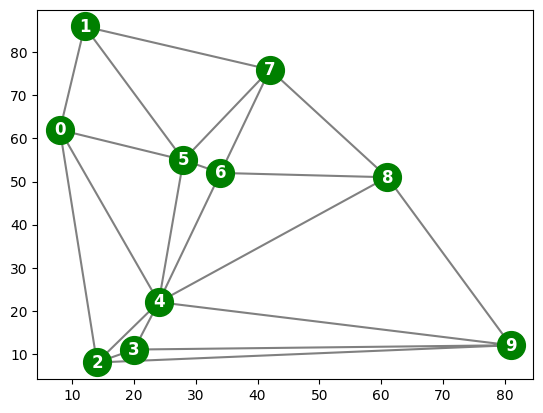

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

### Bài 1 — Quan sát đồ thị phẳng tạo bởi Delaunay

Notebook gốc sử dụng `np.random.seed(1111)` và `n = 10`, sau đó sinh tọa độ hai chiều và sắp xếp theo hoành độ trước khi tính phép tam giác hóa Delaunay bằng `scipy.spatial.Delaunay`. Các đoạn thẳng ở hình trên biểu diễn cạnh của đồ thị; các số `0, 1, …, 9` là nhãn đỉnh.

Tọa độ điểm chỉ được dùng để **tạo cấu trúc quan hệ kề**. Trong bài toán CSP tô màu, biến cần gán là màu của mỗi đỉnh, không phải tọa độ của đỉnh. Giữ cùng seed giúp chúng ta so sánh miền 3/4 màu trên **đúng một đồ thị**.

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

### Bài 1 — Danh sách `neighbors` và tập cạnh không hướng

`tri.vertex_neighbor_vertices` trả về dạng lưu trữ nén: `indices[indptr[i]:indptr[i+1]]` là danh sách các đỉnh kề với đỉnh `i`. Vì đồ thị không hướng, nếu `j` xuất hiện trong `neighbors[i]` thì `i` cũng xuất hiện trong `neighbors[j]`.

Một cạnh `(i, j)` không hướng chỉ cần lưu **một lần**. Điều kiện `i < j` được sử dụng để tránh tạo trùng ràng buộc `(i, j)` và `(j, i)`. Nó **không** có nghĩa đồ thị là có hướng. Công thức kiểm tra: `sum(degree(i)) = 2 × |E|`.

In [3]:
# Bài 1 — Liệt kê neighbors và kiểm tra số cạnh của đồ thị gốc
edge_list = sorted((i, int(j)) for i, adjacent in enumerate(neighbors)
                   for j in adjacent if i < int(j))
neighbor_rows = [(i, [int(j) for j in adjacent]) for i, adjacent in enumerate(neighbors)]

print('Danh sách láng giềng của từng đỉnh:')
for i, adj in neighbor_rows:
    print(f'  {i}: {adj} | bậc = {len(adj)}')

print(f'\nSố biến/đỉnh n = {n}')
print(f'Số cạnh không hướng |E| = {len(edge_list)}')
print(f'Tổng bậc = {sum(len(adj) for _, adj in neighbor_rows)}')
print(f'Tập cạnh = {edge_list}')

assert len(neighbors) == n
assert all(i in neighbors[int(j)] for i, adj in neighbor_rows for j in adj), 'Quan hệ kề không đối xứng'
assert sum(len(adj) for _, adj in neighbor_rows) == 2 * len(edge_list)
assert len(edge_list) == len(set(edge_list))
print('Kiểm tra đối xứng và không đếm trùng cạnh: PASS')

Danh sách láng giềng của từng đỉnh:
  0: [1, 2, 4, 5] | bậc = 4
  1: [0, 5, 7] | bậc = 3
  2: [0, 3, 4, 9] | bậc = 4
  3: [2, 4, 9] | bậc = 3
  4: [0, 2, 3, 5, 6, 8, 9] | bậc = 7
  5: [0, 1, 4, 6, 7] | bậc = 5
  6: [4, 5, 7, 8] | bậc = 4
  7: [1, 5, 6, 8] | bậc = 4
  8: [4, 6, 7, 9] | bậc = 4
  9: [2, 3, 4, 8] | bậc = 4

Số biến/đỉnh n = 10
Số cạnh không hướng |E| = 21
Tổng bậc = 42
Tập cạnh = [(0, 1), (0, 2), (0, 4), (0, 5), (1, 5), (1, 7), (2, 3), (2, 4), (2, 9), (3, 4), (3, 9), (4, 5), (4, 6), (4, 8), (4, 9), (5, 6), (5, 7), (6, 7), (6, 8), (7, 8), (8, 9)]
Kiểm tra đối xứng và không đếm trùng cạnh: PASS


The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [4]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

### Bài 1 — Xác định ba thành phần \(X, D, C\) của CSP

Bài toán tô màu đồ thị được mô hình hóa bằng bộ ba \(CSP=(X,D,C)\):

- **Tập biến \(X\)**: `{'0', '1', …, '9'}` (chuỗi ký tự, theo code gốc). Mỗi biến là **một đỉnh**.
- **Miền giá trị \(D_i\)**: với 4 màu là `{red, blue, green, orange}`; với 3 màu là `{red, blue, green}`. Mỗi đỉnh chọn một màu trong miền của nó.
- **Tập ràng buộc \(C\)**: với mỗi cạnh không hướng `(i, j)`, yêu cầu `color(i) != color(j)`.

Notebook gốc lưu `csp` dưới dạng dictionary với ba khóa `variables`, `domains` và `constraints`. Mỗi phần tử của `constraints` là bộ đôi các **tên biến** (chuỗi), không phải tọa độ hay tên màu.

**Chú ý:** Thay đổi từ bốn màu sang ba màu chỉ đổi miền giá trị, không thay đổi đồ thị hoặc tập cạnh. Số lượng phép gán đầy đủ theo miền lần lượt là \(4^{10}\) và \(3^{10}\), nhưng **đa số các phép gán đó có thể vi phạm ràng buộc**.

In [5]:
# Bài 1 — Tạo hai CSP trên CÙNG đồ thị, không sửa csp gốc (4 màu)
colors4 = ['red', 'blue', 'green', 'orange']
colors3 = ['red', 'blue', 'green']

# Sao chép độc lập từng domain, tránh việc sửa một CSP ảnh hưởng CSP còn lại
def with_colors(csp_base, colors):
    return {
        'variables': list(csp_base['variables']),
        'domains': {v: list(colors) for v in csp_base['variables']},
        'constraints': tuple(csp_base['constraints']),
    }

csp4 = with_colors(csp, colors4)
csp3 = with_colors(csp, colors3)

print('X =', csp4['variables'])
print('D_i (4 màu) =', csp4['domains']['0'])
print('D_i (3 màu) =', csp3['domains']['0'])
print('C: với mỗi (i,j) thuộc E, yêu cầu color(i) != color(j)')
print('Số ràng buộc nhị phân (mỗi cạnh một ràng buộc):', len(csp4['constraints']))
print('Số phép gán đầy đủ tiềm năng với 4 màu =', 4 ** len(csp4['variables']))
print('Số phép gán đầy đủ tiềm năng với 3 màu =', 3 ** len(csp3['variables']))
assert len(csp4['constraints']) == len(edge_list) == len(csp3['constraints'])
assert all(int(i) < int(j) for i,j in csp4['constraints'])
assert all(set(v) == set(colors4) for v in csp4['domains'].values())
assert all(set(v) == set(colors3) for v in csp3['domains'].values())

X = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
D_i (4 màu) = ['red', 'blue', 'green', 'orange']
D_i (3 màu) = ['red', 'blue', 'green']
C: với mỗi (i,j) thuộc E, yêu cầu color(i) != color(j)
Số ràng buộc nhị phân (mỗi cạnh một ràng buộc): 21
Số phép gán đầy đủ tiềm năng với 4 màu = 1048576
Số phép gán đầy đủ tiềm năng với 3 màu = 59049


### Bài 1 — Phân biệt phép gán đầy đủ và phép gán hợp lệ

Một phép gán **đầy đủ (complete)** là phép gán đã có giá trị cho *mọi biến*. Nó có thể vẫn **không hợp lệ** nếu hai đỉnh kề nhau cùng màu (hoặc màu nằm ngoài miền quy định).

Một **nghiệm CSP** phải đồng thời: (1) gán đầy đủ mọi biến, (2) gán màu thuộc miền tương ứng, và (3) thỏa **tất cả** ràng buộc khác màu trên các cạnh. Phép gán từng phần có thể chưa vi phạm ràng buộc nào, nhưng chưa được gọi là nghiệm vì chưa đầy đủ.

Ví dụ minh họa ngay dưới đây cố tình gán mọi đỉnh thành màu đỏ: đây là phép gán **đầy đủ nhưng không hợp lệ**. Trong Bài 2, các hàm `complete()` và `consistent()` của notebook gốc sẽ được kiểm thử kỹ hơn.

In [6]:
# Minh họa khái niệm, chưa thay thế các bài kiểm thử complete()/consistent() của Bài 2
all_red = {v: 'red' for v in csp4['variables']}
partial = {'0': 'red'}

def describe_assignment(assignment, model):
    full = all(v in assignment for v in model['variables'])
    in_domain = all(v in model['variables'] and color in model['domains'][v]
                    for v, color in assignment.items())
    bad_edges = [(u, v) for u, v in model['constraints']
                 if u in assignment and v in assignment and assignment[u] == assignment[v]]
    consistent_so_far = in_domain and len(bad_edges) == 0
    solution = full and consistent_so_far
    return full, consistent_so_far, solution, len(bad_edges)

for label, a in [('Phép gán từng phần', partial), ('Tất cả đỉnh màu đỏ', all_red)]:
    full, consistent_now, solution, n_bad = describe_assignment(a, csp4)
    print(f'{label}: complete={full}, consistent={consistent_now}, '
          f'solution={solution}, số cạnh vi phạm={n_bad}')

assert describe_assignment(partial, csp4)[:3] == (False, True, False)
assert describe_assignment(all_red, csp4)[:3] == (True, False, False)

Phép gán từng phần: complete=False, consistent=True, solution=False, số cạnh vi phạm=0
Tất cả đỉnh màu đỏ: complete=True, consistent=False, solution=False, số cạnh vi phạm=21


## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [7]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [8]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


## Implement Simple Backtracking Search

In [9]:
# TODO: implement variable ordering. Choose variable with the minimum-remaining-values (MRV)
def select_unassigned_var(assignment, csp):
    if(complete(assignment, csp)): return(None)
    
    return(csp['variables'][np.where([not v in assignment.keys() for v in csp['variables']])[0][0]])

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =", 
     select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 2


In [10]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0
    
    assignment = backtrack({}, csp)
    
    print(f"Checked nodes: {COUNT}")
    
    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT
    
    COUNT += 1
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    # TODO: implement value ordering. Use the least-constraining-value heuristic. 
    # for val in order_domain(assignment, var, csp)
    for val in csp['domains'][var]:
        assignment[var] = val
        
        if VERBOSE: print(f"Checking: {assignment}")
        
        if consistent(assignment, csp):
            
            #TODO: add inference for early failing (forward checking, )
            # if inference_fails(assignment, csp): return(None)
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)
                
        del assignment[var]
        
    if VERBOSE: print(f"Backtracking")
    return(None) 

## Run Backtracking Search on the Random Problem

In [11]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
CPU times: user 201 μs, sys: 37 μs, total: 238 μs
Wall time: 240 μs


{'0': 'red',
 '1': 'blue',
 '2': 'blue',
 '3': 'red',
 '4': 'green',
 '5': 'orange',
 '6': 'red',
 '7': 'green',
 '8': 'blue',
 '9': 'orange'}

Plot the resulting coloring

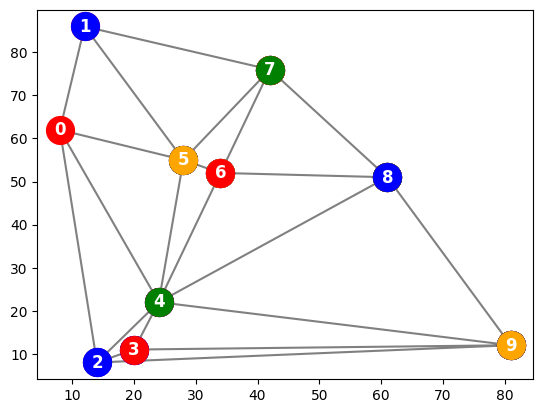

In [12]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

### Bài 1 — Thực nghiệm domain 4 màu và 3 màu trên cùng đồ thị

Để quan sát **khả năng thỏa mãn CSP** (ngoài việc chỉ thay danh sách màu), phần này gọi hàm Backtracking **cơ bản đã có sẵn trong notebook gốc** làm công cụ kiểm chứng, chưa thực hiện các TODO về MRV, LCV và Forward Checking (dành cho Bài 3–4).

Đồ thị được cố định bởi seed `1111` và gồm 10 đỉnh, 21 cạnh. Đồ thị cụ thể này có một **đồ thị con đầy đủ bốn đỉnh \(K_4\)**. Do bốn đỉnh đó đôi một kề nhau, phải sử dụng **ít nhất 4 màu khác nhau** cho chúng. Vì thế trường hợp 3 màu *không có nghiệm*, không phải thuật toán ngẫu nhiên chạy lỗi hay hết hạn mức. Trường hợp 4 màu được minh chứng bằng phép gán đầy đủ, không vi phạm cạnh.

Đây là kết luận cho **đồ thị đang khảo sát**; không suy rộng rằng mọi đồ thị phẳng đều cần bốn màu hoặc đều không tô được bằng ba màu.

In [13]:
# Bài 1 — Dùng hàm Backtracking gốc đã định nghĩa bên trên để kiểm chứng 3/4 màu
from itertools import combinations
from pathlib import Path
import csv
import time

output_dir = Path('Lab04_Bai1_Results')
output_dir.mkdir(parents=True, exist_ok=True)

# Tìm một K4 trực tiếp từ tập cạnh, làm chứng cứ việc tô 3 màu là bất khả thi
edgeset = set(edge_list)
k4_candidates = [four for four in combinations(range(n), 4)
                 if all((a, b) in edgeset for a, b in combinations(four, 2))]
print('Các đồ thị con K4:', k4_candidates)
assert k4_candidates, 'Không tìm thấy K4, không thể dùng lập luận K4 cho 3 màu.'

summary_rows = []
solutions = {}
for palette, model in [('4 màu', csp4), ('3 màu', csp3)]:
    start = time.perf_counter()
    solution = backtrack_search(model)    # hàm nguyên bản của giảng viên
    elapsed_ms = (time.perf_counter() - start) * 1000
    nodes_checked = COUNT             # COUNT của notebook gốc
    solutions[palette] = solution
    if solution is None:
        full = False
        valid = False
        bad_edges = None
    else:
        full, consistent_now, valid, bad_edges = describe_assignment(solution, model)
        assert full and consistent_now and valid
    summary_rows.append({
        'domain': palette,
        'n_vertices': n,
        'n_edges': len(edge_list),
        'n_colors': len(model['domains']['0']),
        'full_assignment_space': len(model['domains']['0'])**n,
        'solution_found': solution is not None,
        'is_complete': full,
        'is_valid_solution': valid,
        'violating_edges': bad_edges,
        'checked_nodes_original_backtracking': nodes_checked,
        'elapsed_ms': round(elapsed_ms, 4),
    })
    print(f'{palette}: nghiệm={solution}, hợp lệ={valid}, '
          f'COUNT={nodes_checked}, thời gian={elapsed_ms:.3f} ms')

assert solutions['4 màu'] is not None
assert solutions['3 màu'] is None

# Xuất bảng kết quả và danh sách neighbors dưới đường dẫn tương đối
with (output_dir / 'Bai1_CSP_Domain_Comparison.csv').open('w', newline='', encoding='utf-8-sig') as f:
    writer = csv.DictWriter(f, fieldnames=list(summary_rows[0].keys()))
    writer.writeheader()
    writer.writerows(summary_rows)
with (output_dir / 'Bai1_CSP_Neighbors.csv').open('w', newline='', encoding='utf-8-sig') as f:
    writer = csv.writer(f)
    writer.writerow(['vertex', 'degree', 'neighbors'])
    for vertex, adjacent in neighbor_rows:
        writer.writerow([vertex, len(adjacent), ','.join(map(str, adjacent))])
with (output_dir / 'Bai1_CSP_Edges.csv').open('w', newline='', encoding='utf-8-sig') as f:
    writer = csv.writer(f)
    writer.writerow(['vertex_u', 'vertex_v'])
    writer.writerows(edge_list)
print(f'Đã xuất 3 file CSV tại: {output_dir}/')

Các đồ thị con K4: [(2, 3, 4, 9)]
Checked nodes: 11
4 màu: nghiệm={'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green', '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}, hợp lệ=True, COUNT=11, thời gian=0.133 ms
Checked nodes: 70
3 màu: nghiệm=None, hợp lệ=False, COUNT=70, thời gian=0.696 ms


Đã xuất 3 file CSV tại: Lab04_Bai1_Results/


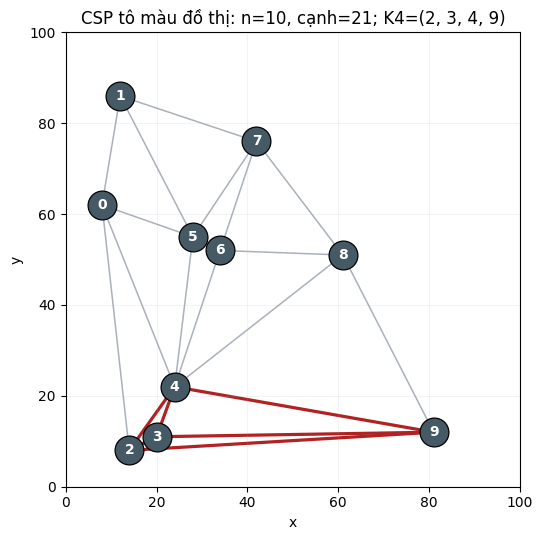

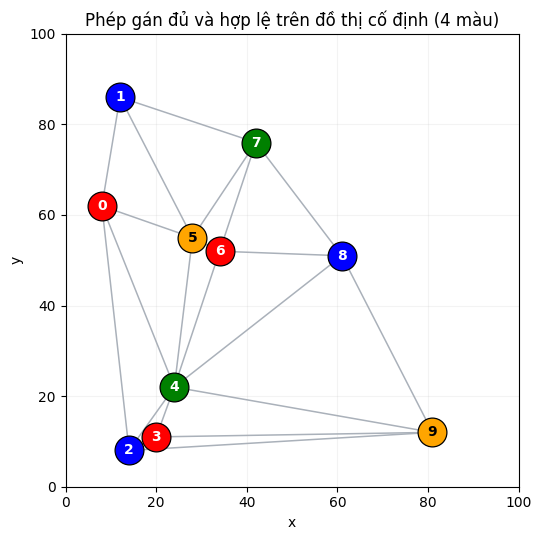

Đã lưu hai hình trong: Lab04_Bai1_Results


In [14]:
# Bài 1 — Trực quan hóa và xuất 2 hình: cấu trúc + tô 4 màu
from matplotlib.lines import Line2D

plt.rcParams['font.family'] = 'DejaVu Sans'

def draw_graph(ax, assignment=None, highlight_k4=False):
    for u, v in edge_list:
        important = highlight_k4 and u in k4_candidates[0] and v in k4_candidates[0]
        ax.plot([points[u, 0], points[v, 0]], [points[u, 1], points[v, 1]],
                color='firebrick' if important else '#aab1ba',
                linewidth=2.3 if important else 1.1,
                zorder=1)
    for v in range(n):
        face = '#455a64' if assignment is None else assignment[str(v)]
        ax.scatter(points[v, 0], points[v, 1], s=430, c=face,
                   edgecolors='black', linewidths=0.9, zorder=3)
        ax.text(points[v, 0], points[v, 1], str(v),
                ha='center', va='center', color='white' if assignment is None or face in ('red','blue','green') else 'black',
                fontsize=10, weight='bold', zorder=4)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(True, alpha=0.15)
    ax.set_xlabel('x')
    ax.set_ylabel('y')

fig, ax = plt.subplots(figsize=(7, 5.5))
draw_graph(ax, highlight_k4=True)
ax.set_title(f'CSP tô màu đồ thị: n={n}, cạnh={len(edge_list)}; K4={k4_candidates[0]}')
fig.tight_layout()
fig.savefig(output_dir / 'Bai1_Delaunay_Graph_K4.png', dpi=170, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7, 5.5))
draw_graph(ax, assignment=solutions['4 màu'])
ax.set_title('Phép gán đủ và hợp lệ trên đồ thị cố định (4 màu)')
fig.tight_layout()
fig.savefig(output_dir / 'Bai1_Valid_Four_Coloring.png', dpi=170, bbox_inches='tight')
plt.show()

print('Đã lưu hai hình trong:', output_dir)

### Bài 1 — Kết luận và nhận xét

1. Delaunay sinh ra **10 đỉnh và 21 cạnh**. Mỗi quan hệ kề được thấy hai lần qua danh sách `neighbors`, nhưng mỗi cạnh chỉ tạo **một ràng buộc bất đẳng thức** nhờ điều kiện `i < j`.
2. `csp['variables']` chứa các **nhãn đỉnh**, `csp['domains']` chứa các **màu được phép**, `csp['constraints']` chứa các **cặp đỉnh kề phải khác màu**. Đây là ba thành phần \(X,D,C\) của CSP.
3. Tô **4 màu** có nghiệm hợp lệ trên đồ thị hiện tại; tô **3 màu** không có nghiệm vì tồn tại \(K_4\) (bốn đỉnh đôi một kề nhau). Giảm miền từ 4 xuống 3 màu còn làm số phép gán đầy đủ tiềm năng giảm từ 1.048.576 xuống 59.049, nhưng đồng thời làm ràng buộc khó thỏa mãn hơn.
4. **Đầy đủ khác hợp lệ**: phép gán mọi đỉnh màu đỏ là đầy đủ nhưng vi phạm mọi cạnh; phép gán từng phần có thể nhất quán nhưng chưa phải nghiệm. Nghiệm CSP yêu cầu **đầy đủ, thuộc miền và thỏa tất cả ràng buộc**.
5. Phần đối chứng dùng **Backtracking gốc**, không thay đổi code MRV/LCV/Forward Checking của giảng viên. `COUNT` và thời gian thu được chỉ mô tả lượt chạy của bộ kiểm chứng; Bài 3 sẽ đánh giá các biến thể Backtracking một cách hệ thống. Các bảng CSV và hình được lưu theo **đường dẫn tương đối**, thuận tiện khi chạy lại notebook.

**Tệp kết quả:** `Lab04_Bai1_Results/Bai1_CSP_Domain_Comparison.csv`, `Bai1_CSP_Neighbors.csv`, `Bai1_CSP_Edges.csv`, `Bai1_Delaunay_Graph_K4.png`, `Bai1_Valid_Four_Coloring.png`. Phần tiếp theo của notebook tiếp tục dành cho các bài thực hành Bài 2–4.

# LAB04 — Bài 2. Kiểm tra tính đầy đủ và nhất quán

**Yêu cầu:** kiểm thử `complete(assignment, csp)` và `consistent(assignment, csp)` với phép gán rỗng, một phần, đầy đủ và trường hợp hai đỉnh kề cùng màu; ghi kết quả mong đợi; giải thích cấu trúc dữ liệu của CSP và phân biệt *phép gán từng phần*, *phép gán đầy đủ* với *nghiệm CSP*.

Bài 2 **tiếp tục trên đúng đồ thị 10 đỉnh và seed 1111 của Bài 1**. Các hàm `complete()` và `consistent()` trong phần code gốc được **giữ nguyên**; không thay thế bằng phiên bản mở rộng, để các bài Backtracking sau vẫn sử dụng đúng cấu trúc mà giảng viên cung cấp.

In [15]:
# Bài 2 — Khảo sát cách lưu CSP và quan hệ giữa hai biến kề
print('Các thành phần của csp:', list(csp.keys()))
print('variables:', csp['variables'])
print('domains["0"]:', csp['domains']['0'])
print('Số biến:', len(csp['variables']))
print('Số ràng buộc:', len(csp['constraints']))

edge_u, edge_v = next(iter(csp4['constraints']))
print('Ví dụ ràng buộc hai đỉnh kề:', (edge_u, edge_v),
      '=>', f'color({edge_u}) != color({edge_v})')

assert isinstance(csp['variables'], list)
assert isinstance(csp['domains'], dict)
assert all(v in csp['domains'] for v in csp['variables'])
assert all(len(edge) == 2 for edge in csp['constraints'])
assert len(csp4['constraints']) == len(edge_list) == 21
print('Kiểm tra cấu trúc X, D, C: PASS')

Các thành phần của csp: ['variables', 'domains', 'constraints']
variables: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
domains["0"]: ['red', 'blue', 'green', 'orange']
Số biến: 10
Số ràng buộc: 21
Ví dụ ràng buộc hai đỉnh kề: ('0', '1') => color(0) != color(1)
Kiểm tra cấu trúc X, D, C: PASS


## 2.1. Phân tích hai hàm của notebook gốc

`assignment` là dictionary, ví dụ `{'0': 'red', '1': 'blue'}`; **khóa** là tên biến/đỉnh (kiểu chuỗi), **giá trị** là màu đã gán. Nếu một biến chưa xuất hiện trong dictionary, biến đó chưa được gán.

- `complete(assignment, csp)` trả về `True` khi **mọi tên biến** trong `csp['variables']` xuất hiện trong `assignment`; không kiểm tra xung đột màu hoặc màu có thuộc miền không.
- `consistent(assignment, csp)` duyệt các cạnh trong `csp['constraints']`. Chỉ khi **cả hai đầu cạnh đã được gán**, hàm mới kiểm tra hai màu khác nhau. Nếu tìm thấy một cạnh có hai đầu cùng màu, hàm trả về `False`. Với phép gán rỗng hoặc một phần không có xung đột giữa các đỉnh đã gán, hàm trả về `True`.

**Lưu ý về mã gốc:** `consistent()` chỉ kiểm tra **ràng buộc khác màu trên cạnh**, **không tự kiểm tra màu có thuộc miền giá trị `domains` hay không**. Để kiểm tra nghiệm CSP theo đúng mô hình \(X,D,C\), ta cần thêm kiểm tra miền riêng, nhưng **không sửa đè hai hàm của giảng viên**.

Điều kiện nghiệm trong Bài 2:

\[
\mathrm{solution}(A)=\mathrm{complete}(A)\ \land\ \mathrm{consistent}(A)\ \land\ \mathrm{domain\_valid}(A).
\]

## 2.2. Các ca kiểm thử và kết quả mong đợi

Sử dụng đồ thị cố định từ Bài 1 và hai đỉnh `edge_u`, `edge_v` thật sự kề nhau. Một nghiệm 4 màu `solutions['4 màu']` đã được Backtracking cơ bản kiểm chứng trong Bài 1.

| Ca | Đầu vào | `complete()` mong đợi | `consistent()` mong đợi | Nghiệm CSP? |
|---|---|---|---|---|
| TC01 | Phép gán rỗng `{}` | False | True | Không |
| TC02 | Một đỉnh được gán | False | True | Không |
| TC03 | Hai đỉnh kề gán **khác** màu | False | True | Không |
| TC04 | Hai đỉnh kề gán **cùng** màu | False | False | Không |
| TC05 | Mọi đỉnh đều `red` | True | False | Không |
| TC06 | Phép tô 4 màu hợp lệ từ Bài 1 | True | True | Có |
| TC07 | Phép gán đầy đủ nhưng một màu là `purple` (ngoài miền) | True | True (theo *hàm gốc*) | Không |
| TC08 | Phép gán đầy đủ chỉ dùng 3 màu, thu từ nghiệm 4 màu | True | False | Không |

TC07 là kiểm thử biên quan trọng: nó cho thấy **tính nhất quán theo ràng buộc cạnh** không thay thế cho **kiểm tra miền giá trị**. Các kiểm thử dùng `assert` để đối chiếu kết quả thực tế với kết quả mong đợi.

In [16]:
# Bài 2 — Chạy 8 ca kiểm thử, đối chiếu kỳ vọng và xuất bảng CSV
from pathlib import Path
from IPython.display import Markdown, display
import csv

bai2_dir = Path('Lab04_Bai2_Results')
bai2_dir.mkdir(parents=True, exist_ok=True)

def domain_valid(assignment, model):
    """Kiểm tra khóa hợp lệ và màu thuộc miền. Giữ nguyên consistent() gốc."""
    return all(v in model['variables'] and value in model['domains'][v]
               for v, value in assignment.items())

def violating_edges(assignment, model):
    """Liệt kê cạnh vi phạm: chỉ khi cả hai đầu đã được gán."""
    return [(u, v) for u, v in model['constraints']
            if u in assignment and v in assignment
            and assignment[u] == assignment[v]]

def is_csp_solution(assignment, model):
    """Nghiệm phải đầy đủ, nhất quán theo cạnh và nằm trong các miền giá trị."""
    return (complete(assignment, model)
            and consistent(assignment, model)
            and domain_valid(assignment, model))

# Phép gán hợp lệ lấy từ Bài 1 — không tạo ngẫu nhiên lại đồ thị.
valid_4 = dict(solutions['4 màu'])
assert is_csp_solution(valid_4, csp4)

full_out_of_domain = dict(valid_4)
full_out_of_domain[edge_u] = 'purple'  # Không bằng màu hợp lệ nào => không gây trùng màu ở cạnh
three_color_full = {v: ('red' if color == 'orange' else color)
                    for v, color in valid_4.items()}

cases_bai2 = [
    ('TC01', 'Phép gán rỗng', {}, csp4, False, True, False),
    ('TC02', 'Một đỉnh được gán', {edge_u:'red'}, csp4, False, True, False),
    ('TC03', 'Hai đỉnh kề khác màu', {edge_u:'red', edge_v:'blue'}, csp4, False, True, False),
    ('TC04', 'Hai đỉnh kề cùng màu', {edge_u:'red', edge_v:'red'}, csp4, False, False, False),
    ('TC05', 'Đầy đủ nhưng tất cả màu đỏ', {v:'red' for v in csp4['variables']}, csp4, True, False, False),
    ('TC06', 'Đầy đủ và hợp lệ (4 màu)', valid_4, csp4, True, True, True),
    ('TC07', 'Đầy đủ, màu ngoài miền', full_out_of_domain, csp4, True, True, False),
    ('TC08', 'Đầy đủ 3 màu nhưng vi phạm cạnh', three_color_full, csp3, True, False, False),
]

rows_bai2 = []
for code, description, assignment, model, exp_complete, exp_consistent, exp_solution in cases_bai2:
    actual_complete = complete(assignment, model)
    actual_consistent = consistent(assignment, model)
    actual_domain = domain_valid(assignment, model)
    actual_solution = is_csp_solution(assignment, model)
    violations = len(violating_edges(assignment, model))
    assert (actual_complete, actual_consistent, actual_solution) == (
        exp_complete, exp_consistent, exp_solution), f'{code}: kết quả không khớp kỳ vọng'
    rows_bai2.append({
        'test_case': code, 'description': description,
        'domain_colors': len(model['domains'][model['variables'][0]]),
        'assigned_vertices': len(assignment),
        'expected_complete': exp_complete, 'actual_complete': actual_complete,
        'expected_consistent': exp_consistent, 'actual_consistent': actual_consistent,
        'domain_valid': actual_domain,
        'expected_solution': exp_solution, 'actual_solution': actual_solution,
        'violating_edges': violations, 'result': 'PASS'
    })

assert rows_bai2[0]['actual_consistent'] is True
assert rows_bai2[4]['violating_edges'] == len(edge_list) == 21
assert rows_bai2[6]['domain_valid'] is False
assert rows_bai2[7]['domain_valid'] is True

csv_path_bai2 = bai2_dir / 'Bai2_CSP_Completeness_Consistency_Tests.csv'
with csv_path_bai2.open('w', newline='', encoding='utf-8-sig') as f:
    writer = csv.DictWriter(f, fieldnames=list(rows_bai2[0].keys()))
    writer.writeheader()
    writer.writerows(rows_bai2)

headers = '| Ca | Kiểu phép gán | Complete | Consistent | Trong miền D | Nghiệm | Cạnh vi phạm |\n'
headers += '|---|---|---|---|---|---|---:|\n'
for row in rows_bai2:
    headers += ('| {test_case} | {description} | {actual_complete} | '
                '{actual_consistent} | {domain_valid} | {actual_solution} | '
                '{violating_edges} |\n').format(**row)
display(Markdown(headers))
print(f'PASS {len(rows_bai2)}/{len(cases_bai2)} ca kiểm thử.')
print('Đã xuất:', csv_path_bai2)

# Bài học quan trọng: phép gán đầy đủ chưa chắc thỏa các cạnh hoặc thuộc miền.
assert complete(cases_bai2[4][2], csp4) and not consistent(cases_bai2[4][2], csp4)
assert complete(full_out_of_domain, csp4) and consistent(full_out_of_domain, csp4)
assert not domain_valid(full_out_of_domain, csp4)


| Ca | Kiểu phép gán | Complete | Consistent | Trong miền D | Nghiệm | Cạnh vi phạm |
|---|---|---|---|---|---|---:|
| TC01 | Phép gán rỗng | False | True | True | False | 0 |
| TC02 | Một đỉnh được gán | False | True | True | False | 0 |
| TC03 | Hai đỉnh kề khác màu | False | True | True | False | 0 |
| TC04 | Hai đỉnh kề cùng màu | False | False | True | False | 1 |
| TC05 | Đầy đủ nhưng tất cả màu đỏ | True | False | True | False | 21 |
| TC06 | Đầy đủ và hợp lệ (4 màu) | True | True | True | True | 0 |
| TC07 | Đầy đủ, màu ngoài miền | True | True | False | False | 0 |
| TC08 | Đầy đủ 3 màu nhưng vi phạm cạnh | True | False | True | False | 3 |


PASS 8/8 ca kiểm thử.
Đã xuất: Lab04_Bai2_Results/Bai2_CSP_Completeness_Consistency_Tests.csv


## 2.3. Diễn giải kết quả kiểm thử

TC01 chứng minh rằng **phép gán rỗng nhất quán một cách hiển nhiên**: chưa có cạnh nào mà cả hai đầu đều được gán nên chưa có điều kiện khác màu bị vi phạm, nhưng phép gán vẫn chưa đầy đủ.

TC02 và TC03 chứng minh một **phép gán từng phần** có thể không xung đột mà **chưa phải nghiệm**. Ngược lại, TC04 phát hiện ngay xung đột khi hai đỉnh kề nhận cùng màu.

TC05 cho thấy `complete() == True` **không suy ra** `consistent() == True`: tô toàn bộ 10 đỉnh màu đỏ là đầy đủ nhưng vi phạm cả **21 cạnh**. TC06 là nghiệm hợp lệ 4 màu, thỏa cả tính đầy đủ, miền giá trị và 21 ràng buộc.

TC07 làm rõ giới hạn của **mã gốc**: `consistent()` không kiểm tra `domains`, nên một phép gán đầy đủ có màu `purple` vẫn có thể trả về `True`. Kiểm tra `domain_valid()` bổ sung giúp phân loại đúng trường hợp này là *không phải nghiệm CSP*.

TC08 và cấu trúc \(K_4\) đã tìm trong Bài 1 cho thấy với **đồ thị cố định này**, ba màu không đủ để tô hợp lệ; vấn đề không phải do `complete()` hay `consistent()` hoạt động sai, mà do không tồn tại phép gán đầy đủ thỏa tất cả ràng buộc trong miền ba màu.

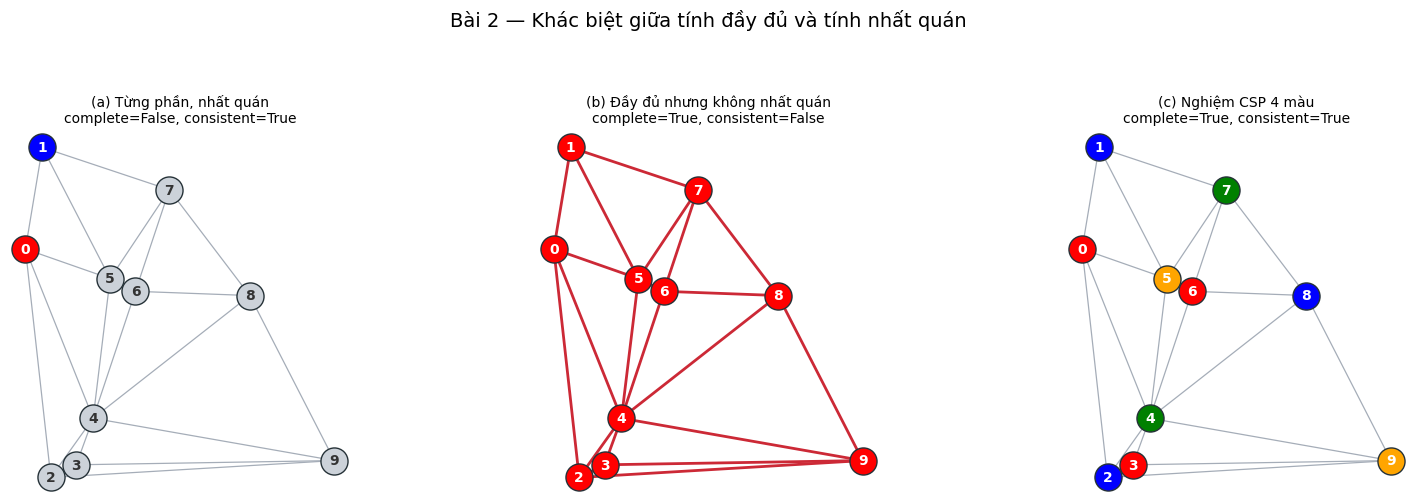

Đã xuất: Lab04_Bai2_Results/Bai2_CSP_Assignment_Examples.png


In [17]:
# Bài 2 — Hình trực quan: gán từng phần, đầy đủ nhưng xung đột, và nghiệm 4 màu
import matplotlib.pyplot as plt

illustrations = [
    ('(a) Từng phần, nhất quán', {edge_u:'red', edge_v:'blue'}, csp4),
    ('(b) Đầy đủ nhưng không nhất quán', {v:'red' for v in csp4['variables']}, csp4),
    ('(c) Nghiệm CSP 4 màu', valid_4, csp4),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.1))
for ax, (title, assignment, model) in zip(axes, illustrations):
    wrong = set(violating_edges(assignment, model))
    for u, v in model['constraints']:
        ui, vi = int(u), int(v)
        ax.plot([points[ui, 0], points[vi, 0]], [points[ui, 1], points[vi, 1]],
                color='#cc2936' if (u, v) in wrong else '#a5adb8',
                linewidth=2.0 if (u,v) in wrong else 0.9, zorder=1)
    for i in range(n):
        name = str(i)
        ax.scatter(points[i,0], points[i,1], s=380,
                   c=assignment.get(name, '#ccd2d9'), edgecolor='#263238', linewidth=1.0, zorder=2)
        ax.text(points[i,0], points[i,1], name, ha='center', va='center',
                fontsize=10, fontweight='bold', color='white' if name in assignment else '#333', zorder=3)
    c = complete(assignment, model)
    s = consistent(assignment, model)
    ax.set_title(f'{title}\ncomplete={c}, consistent={s}', fontsize=10)
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
fig.suptitle('Bài 2 — Khác biệt giữa tính đầy đủ và tính nhất quán', fontsize=14)
fig.tight_layout(rect=(0,0,1,0.91))
png_path_bai2 = bai2_dir / 'Bai2_CSP_Assignment_Examples.png'
fig.savefig(png_path_bai2, dpi=180, bbox_inches='tight', facecolor='white')
plt.show()
print('Đã xuất:', png_path_bai2)


## 2.4. Kết luận Bài 2

Đồ thị của Bài 1 được lưu ở `csp` dưới dạng **ba thành phần**: `variables` (tên đỉnh), `domains` (miền màu theo từng đỉnh) và `constraints` (các cạnh yêu cầu khác màu). Phép gán được lưu bằng dictionary, có thể gán ít hơn \(n\) biến hoặc gán đủ \(n\) biến.

Qua **8/8 ca kiểm thử đạt**, nhận thấy:

- `complete()` trả lời *“đã gán hết biến chưa?”*, không đánh giá xung đột.
- `consistent()` của giảng viên trả lời *“các cạnh có cả hai đầu đã gán có khác màu không?”*, không kiểm tra màu ngoài miền.
- **Nghiệm CSP** phải đầy đủ, thỏa các cạnh **và** mọi giá trị gán thuộc miền cho phép. Vì vậy, `complete()` **không đồng nghĩa** với `consistent()`; thậm chí cả hai giá trị cùng `True` chưa đủ để xác nhận nghiệm nếu không kiểm tra miền.

Dữ liệu được xuất sang `Lab04_Bai2_Results/` (CSV kiểm thử và hình minh họa). Phần Backtracking gốc và các TODO về MRV, LCV, Forward Checking, Min-Conflicts vẫn được giữ nguyên cho **Bài 3–4**.

# LAB04 — Bài 3. Backtracking Search và thứ tự chọn biến

## 3.1. Mục tiêu và nguyên lý

Sử dụng lại **đồ thị Delaunay 10 đỉnh, 21 cạnh, seed = 1111** ở Bài 1 và kiểm tra nghiệm ở Bài 2; không phát sinh đồ thị mới. So sánh thuật toán `backtrack_search(csp)` **nguyên bản** với hai phiên bản mở rộng: **MRV** và **MRV + LCV**. Thử cả hai miền 4 màu và 3 màu.

**Backtracking Search:** bắt đầu với phép gán rỗng `{}`, chọn một biến chưa gán, lần lượt thử màu thuộc miền của biến. Nếu phép gán từng phần không nhất quán, nhánh đó bị loại; nếu nhất quán, tiếp tục tìm kiếm đệ quy. Khi phép gán đầy đủ được xây dựng, trả về nghiệm; khi đã thử hết các lựa chọn, quay lui.

**COUNT của notebook gốc:** tăng một lần *mỗi khi hàm `backtrack()` được gọi* (gồm nút gốc và các nút đã nhất quán được mở rộng đệ quy). COUNT **không phải** số màu được thử trên mọi nút; phần mở rộng ghi thêm chỉ số `attempts` để đếm số lần thử `assignment[var] = color`, bao gồm cả thử thất bại. Hai chỉ số cần được giữ riêng khi so sánh.

**Chú ý:** notebook gốc dùng `select_unassigned_var()` lấy biến chưa gán đầu tiên, rồi thử giá trị theo thứ tự trong `csp['domains'][var]`. Để tránh thay đổi kết quả của Bài 1–2 và giữ TODO Forward Checking cho Bài 4, phiên bản MRV/LCV dưới đây được viết **thành các hàm bổ sung độc lập**, không ghi đè các hàm gốc.

## 3.2. Heuristic Minimum Remaining Values (MRV) và Least Constraining Value (LCV)

**Miền còn hợp lệ** với biến `v` tại phép gán một phần `A`:

\[
D_v^{\mathrm{valid}}(A) = \{c \in D_v : \forall u \in N(v) \cap \mathrm{dom}(A),\ c \neq A[u] \}.
\]

- **MRV** chọn biến chưa gán `v` có số lượng màu còn hợp lệ \(\lvert D_v^{\mathrm{valid}}(A)\rvert\) nhỏ nhất. Nếu bằng nhau, giữ thứ tự `csp['variables']` như trong notebook gốc; không dùng degree heuristic bổ sung, để so sánh đúng riêng tác động của MRV.
- **LCV** áp dụng *sau khi đã chọn biến*: với màu `c` hợp lệ của `v`, đếm số miền hợp lệ của các đỉnh kề **chưa gán** sẽ bị mất màu `c` nếu gán `v=c`. Ưu tiên màu có mức loại trừ thấp nhất, hòa điểm theo thứ tự màu trong domain gốc.
- MRV chỉ tính miền có thể dùng từ các ràng buộc với **đỉnh đã gán**; chưa làm Forward Checking hay lan truyền miền. Phần Forward Checking được giữ lại cho Bài 4.

Việc tính MRV/LCV có chi phí kiểm tra miền, do đó **COUNT nhỏ hơn không luôn đồng nghĩa thời gian chạy nhỏ hơn**.

In [18]:
# Bài 3 — Xây dựng thông tin kề từ constraints, không sửa dữ liệu CSP gốc.
from collections import defaultdict
from time import perf_counter
from pathlib import Path
import csv

bai3_dir = Path('Lab04_Bai3_Results')
bai3_dir.mkdir(parents=True, exist_ok=True)

def constraint_neighbors(model):
    adj = {v: set() for v in model['variables']}
    for u, v in model['constraints']:
        adj[u].add(v)
        adj[v].add(u)
    return adj

def remaining_colors(assignment, var, model, adjacency=None):
    """Màu không trùng với đỉnh kề đã gán; không thay đổi domain gốc."""
    adjacency = constraint_neighbors(model) if adjacency is None else adjacency
    forbidden = {assignment[u] for u in adjacency[var] if u in assignment}
    return [color for color in model['domains'][var] if color not in forbidden]

def select_unassigned_var_mrv(assignment, model, adjacency=None):
    """MRV thuần: số màu hợp lệ ít nhất; hòa theo thứ tự variables gốc."""
    adjacency = constraint_neighbors(model) if adjacency is None else adjacency
    unassigned = [v for v in model['variables'] if v not in assignment]
    if not unassigned:
        return None
    return min(unassigned, key=lambda v: len(remaining_colors(assignment, v, model, adjacency)))

def order_domain_lcv(assignment, var, model, adjacency=None):
    """LCV: màu tác động ít nhất đến các đỉnh kề chưa gán, hòa theo thứ tự domain."""
    adjacency = constraint_neighbors(model) if adjacency is None else adjacency
    valid = remaining_colors(assignment, var, model, adjacency)
    unassigned_neighbors = [u for u in adjacency[var] if u not in assignment]

    def eliminated_count(color):
        return sum(color in remaining_colors(assignment, u, model, adjacency)
                   for u in unassigned_neighbors)

    return sorted(valid, key=eliminated_count)  # sorted ổn định, giữ thứ tự domain khi bằng nhau

print('MRV/LCV đã định nghĩa. Số đỉnh:', len(csp4['variables']),
      '| Số cạnh:', len(csp4['constraints']))


MRV/LCV đã định nghĩa. Số đỉnh: 10 | Số cạnh: 21


## 3.3. Cài đặt Backtracking có thể lựa chọn chiến lược

Hàm `backtrack_search_ordered(model, variable_order, value_order)` giữ **cùng ràng buộc, miền màu, cách đếm nút và phép kiểm tra nhất quán** như Backtracking cơ bản, chỉ thay thứ tự biến/giá trị. Các nút được đếm khi bắt đầu một lượt đệ quy, kể cả gốc. Bổ sung `attempts`, `backtracks`, `max_depth` để giải thích chi phí.

Giả định thuật toán chỉ được gọi với CSP hợp lệ có các ràng buộc bất đẳng thức nhị phân như mô hình bài này; một nghiệm được xác nhận bằng `is_csp_solution()` ở Bài 2.

In [19]:
# Bài 3 — Các biến thể độc lập, không ghi đè backtrack_search() gốc.
def backtrack_search_ordered(model, variable_order='first', value_order='original'):
    assert variable_order in ('first', 'mrv')
    assert value_order in ('original', 'lcv')
    adj = constraint_neighbors(model)
    stats = {'COUNT': 0, 'attempts': 0, 'backtracks': 0, 'max_depth': 0}
    assign = {}

    def dfs():
        stats['COUNT'] += 1   # giống COUNT gốc: 1 lần mỗi lời gọi đệ quy
        stats['max_depth'] = max(stats['max_depth'], len(assign))
        if complete(assign, model):
            return dict(assign)

        if variable_order == 'mrv':
            var = select_unassigned_var_mrv(assign, model, adj)
        else:
            var = next(v for v in model['variables'] if v not in assign)

        if value_order == 'lcv':
            palette = order_domain_lcv(assign, var, model, adj)
        else:
            palette = model['domains'][var]

        for color in palette:
            stats['attempts'] += 1
            assign[var] = color
            if consistent(assign, model):  # đúng hàm kiểm tra ràng buộc của giảng viên
                found = dfs()
                if found is not None:
                    return found
            del assign[var]
        stats['backtracks'] += 1
        return None

    start = perf_counter()
    solution = dfs()
    elapsed_ms = (perf_counter() - start) * 1000
    return solution, {**stats, 'elapsed_ms': elapsed_ms}

# Kiểm chứng MRV trên phép gán từng phần: có thể chọn khác 'biến chưa gán đầu tiên'.
adj4 = constraint_neighbors(csp4)
example_partial = {'0': 'red', '1': 'blue'}
first_unassigned = next(v for v in csp4['variables'] if v not in example_partial)
mrv_choice = select_unassigned_var_mrv(example_partial, csp4, adj4)
print('Phép gán minh họa:', example_partial)
print('Biến đầu tiên chưa gán:', first_unassigned, '| MRV chọn:', mrv_choice)
print('Số màu hợp lệ:', {v: len(remaining_colors(example_partial, v, csp4, adj4))
                        for v in csp4['variables'] if v not in example_partial})
assert mrv_choice in csp4['variables'] and mrv_choice not in example_partial
assert len(remaining_colors(example_partial, mrv_choice, csp4, adj4)) == min(
    len(remaining_colors(example_partial, v, csp4, adj4))
    for v in csp4['variables'] if v not in example_partial)


Phép gán minh họa: {'0': 'red', '1': 'blue'}
Biến đầu tiên chưa gán: 2 | MRV chọn: 5
Số màu hợp lệ: {'2': 3, '3': 4, '4': 3, '5': 2, '6': 4, '7': 3, '8': 4, '9': 4}


## 3.4. Thực nghiệm trên cùng đồ thị 10 đỉnh: 4 màu và 3 màu

So sánh **Baseline (first/original)**, **MRV (mrv/original)** và **MRV+LCV (mrv/lcv)**. Đối với mỗi miền màu, dùng lại 10 đỉnh và 21 cạnh gốc; đo `COUNT`, số lần thử gán (`attempts`), số lần quay lui, độ sâu lớn nhất và thời gian bằng `perf_counter()`.

Để so sánh thời gian ít nhiễu hơn, chạy mỗi chiến lược nhiều lần (20 lần) trên **cùng CSP** và lấy trung vị. `COUNT`, `attempts`, `backtracks` của thuật toán xác định không đổi giữa các lần chạy. Đo thời gian của *hàm tìm kiếm*, không gồm xuất bảng/hình. Với Baseline, dùng chính hàm gốc `backtrack_search(csp)` (in COUNT ra output); thời gian được đo riêng và kết quả đối chiếu với MRV/LCV.

**Kiểm chứng vô nghiệm 3 màu:** đồ thị cố định chứa clique K₄ trên `{2, 3, 4, 9}`. Bốn đỉnh đôi một kề nhau phải mang bốn màu khác nhau, vì vậy không thể thỏa bằng ba màu. Các thuật toán quay lui vét cạn đều phải trả về `None`. Điều này không có nghĩa thuật toán sai hay bị hết thời gian.

In [20]:
# Bài 3 — Đo Baseline gốc và các heuristic trên cùng hai CSP.
from contextlib import redirect_stdout
from io import StringIO
import statistics

STRATEGIES = [
    ('Baseline', 'first', 'original'),
    ('MRV', 'mrv', 'original'),
    ('MRV + LCV', 'mrv', 'lcv'),
]
MODELS_BAI3 = [('4 màu', csp4), ('3 màu', csp3)]
REPEATS_BAI3 = 20
rows_bai3 = []
raw_bai3 = []
solutions_bai3 = {}

for palette, model in MODELS_BAI3:
    for name, var_policy, value_policy in STRATEGIES:
        measurements = []
        final_solution = None
        final_stats = None
        for trial in range(REPEATS_BAI3):
            if name == 'Baseline':
                # Đo đúng hàm backtrack_search(csp) của notebook gốc, không thay code.
                start = perf_counter()
                with redirect_stdout(StringIO()):
                    candidate = backtrack_search(model)
                elapsed_ms = (perf_counter() - start) * 1000
                # COUNT của gốc đo số nút; attempts riêng đo ở bản first/original
                # và đối chiếu nghiệm/COUNT, không cộng thời gian đối chiếu vào benchmark.
                candidate_stats = {'COUNT': COUNT, 'elapsed_ms': elapsed_ms}
            else:
                candidate, candidate_stats = backtrack_search_ordered(
                    model, var_policy, value_policy)
            valid = candidate is not None and is_csp_solution(candidate, model)
            if palette == '4 màu':
                assert valid, f'{name}: không tìm được nghiệm bốn màu'
            else:
                assert candidate is None, f'{name}: ba màu phải vô nghiệm (do K4)'
            final_solution = candidate
            final_stats = candidate_stats
            measurements.append(elapsed_ms if name == 'Baseline' else candidate_stats['elapsed_ms'])
            raw_bai3.append({'domain': palette, 'algorithm': name, 'trial': trial + 1,
                             'elapsed_ms': round(measurements[-1], 6),
                             'COUNT': candidate_stats['COUNT']})

        if name == 'Baseline':
            # Số attempts/backtracks lấy từ bản độc lập cùng first/original;
            # COUNT phải trùng với phiên bản gốc.
            control_sol, control_stats = backtrack_search_ordered(model, 'first', 'original')
            assert control_sol == final_solution and control_stats['COUNT'] == final_stats['COUNT']
            extra = control_stats
        else:
            extra = final_stats
        results_row = {
            'domain': palette, 'algorithm': name,
            'n_vertices': len(model['variables']), 'n_edges': len(model['constraints']),
            'colors': len(model['domains'][model['variables'][0]]),
            'solved': bool(final_solution is not None),
            'COUNT_nodes': final_stats['COUNT'], 'attempts': extra['attempts'],
            'backtracks': extra['backtracks'], 'max_depth': extra['max_depth'],
            'median_elapsed_ms': round(statistics.median(measurements), 6),
            'mean_elapsed_ms': round(statistics.mean(measurements), 6),
            'repeat_count': REPEATS_BAI3,
        }
        rows_bai3.append(results_row)
        solutions_bai3[(palette, name)] = final_solution

# Không làm thay đổi mô hình hoặc kết quả hai bài trước.
assert len(rows_bai3) == 6 and len(raw_bai3) == 6 * REPEATS_BAI3
assert len(csp4['constraints']) == len(csp3['constraints']) == 21
assert all(is_csp_solution(solutions_bai3[('4 màu', name)], csp4)
           for name, _, _ in STRATEGIES)
assert all(solutions_bai3[('3 màu', name)] is None for name, _, _ in STRATEGIES)

for filename, entries in [('Bai3_Backtracking_Comparison.csv', rows_bai3),
                          ('Bai3_Backtracking_Timing_Raw.csv', raw_bai3)]:
    path = bai3_dir / filename
    with path.open('w', newline='', encoding='utf-8-sig') as f:
        writer = csv.DictWriter(f, fieldnames=list(entries[0]))
        writer.writeheader()
        writer.writerows(entries)

from IPython.display import display, Markdown
head = ('| Miền | Thuật toán | Nghiệm | COUNT | Attempts | Quay lui | Độ sâu | '
        'Trung vị (ms) |\n|---|---|---|---:|---:|---:|---:|---:|\n')
lines = []
for row in rows_bai3:
    lines.append(f"| {row['domain']} | {row['algorithm']} | {row['solved']} | "
                 f"{row['COUNT_nodes']} | {row['attempts']} | {row['backtracks']} | "
                 f"{row['max_depth']} | {row['median_elapsed_ms']:.4f} |")
display(Markdown(head + '\n'.join(lines)))
print('Đã lưu bảng và thời gian gốc tại:', bai3_dir)


| Miền | Thuật toán | Nghiệm | COUNT | Attempts | Quay lui | Độ sâu | Trung vị (ms) |
|---|---|---|---:|---:|---:|---:|---:|
| 4 màu | Baseline | True | 11 | 23 | 0 | 10 | 0.0712 |
| 4 màu | MRV | True | 11 | 24 | 0 | 10 | 0.0887 |
| 4 màu | MRV + LCV | True | 11 | 10 | 0 | 10 | 0.1132 |
| 3 màu | Baseline | False | 70 | 210 | 70 | 7 | 0.4831 |
| 3 màu | MRV | False | 34 | 102 | 34 | 6 | 0.2984 |
| 3 màu | MRV + LCV | False | 34 | 33 | 34 | 6 | 0.4171 |

Đã lưu bảng và thời gian gốc tại: Lab04_Bai3_Results


## 3.5. Trực quan hóa nghiệm và hiệu quả thứ tự biến/giá trị

Biểu đồ COUNT cho biết số lời gọi đệ quy, không phải số lần thử màu. Ảnh tô màu dùng chính nghiệm từ từng phương pháp trên **cùng đồ thị 4 màu**; nghiệm 3 màu không tồn tại do K₄. Khi các heuristic trả về cùng COUNT, kết quả đó không có nghĩa MRV/LCV được triển khai sai: bài toán có thể đủ thuận lợi để mọi thứ tự đều đi thẳng đến nghiệm (với 4 màu) hoặc phải kiểm tra đủ nhiều trường hợp (với 3 màu).

**Lưu ý cách đếm attempts:** `order_domain_lcv()` trong hiện thực này chỉ duyệt những màu đã hợp lệ với các đỉnh được gán (bỏ qua màu chắc chắn vi phạm), rồi sắp xếp chúng theo LCV. Trong khi Baseline và MRV vẫn thử toàn bộ màu gốc, kể cả màu sẽ bị `consistent()` loại. Vì vậy phần giảm số lần thử màu của **MRV + LCV** đến từ cả việc loại màu đang xung đột lẫn thay đổi thứ tự giá trị, **không thể quy toàn bộ mức giảm đó cho LCV thuần túy**. CNT/COUNT là số nút đệ quy nên vẫn so sánh được theo cùng định nghĩa.


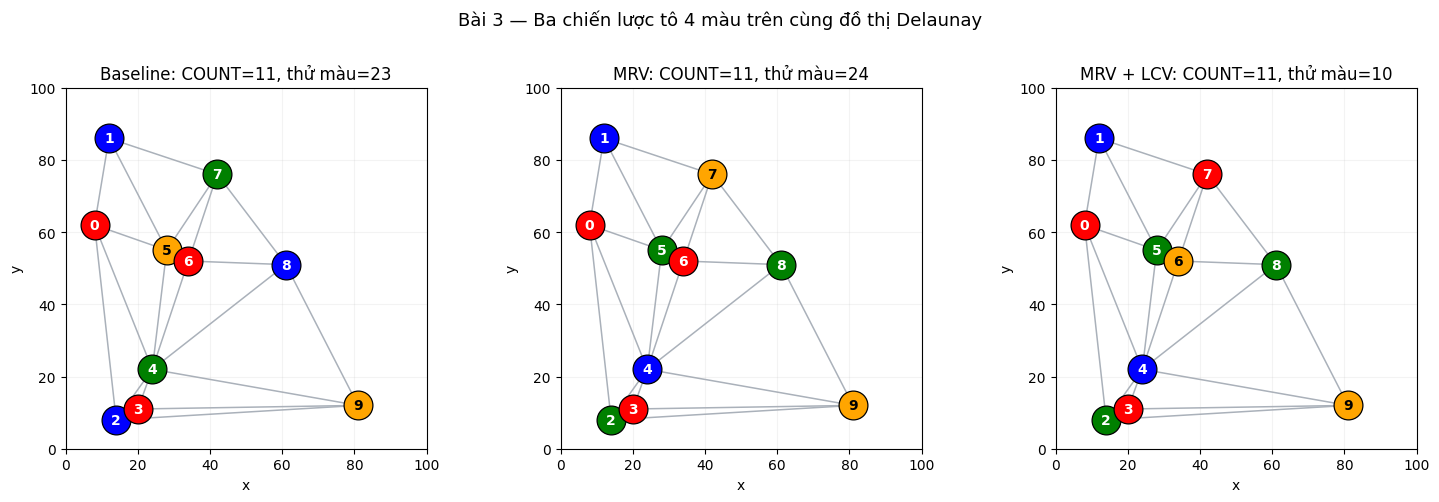

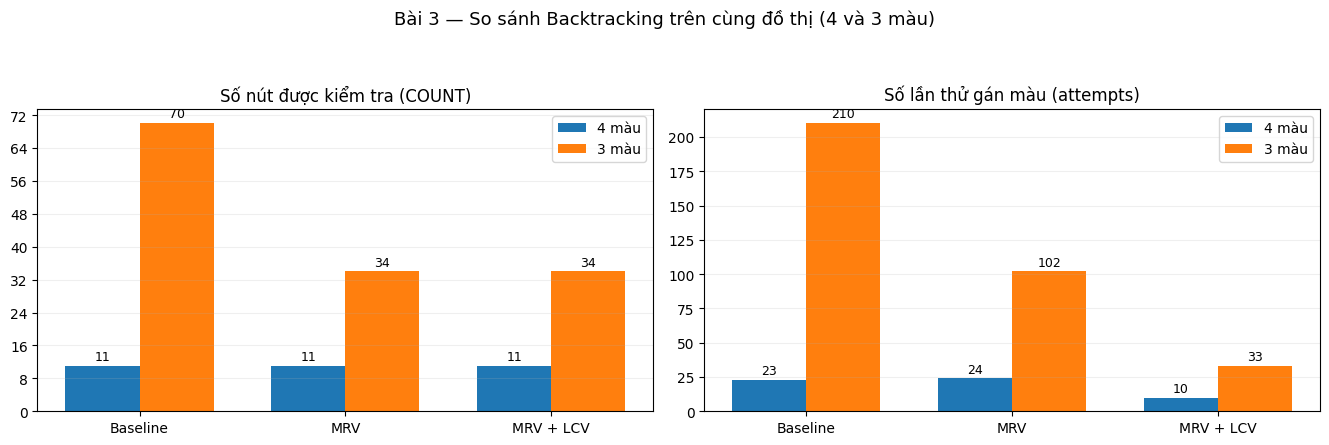

In [21]:
# Bài 3 — Hai hình: nghiệm ba chiến lược và so sánh COUNT/attempts.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.9))
for ax, (name, _, _) in zip(axes, STRATEGIES):
    draw_graph(ax, assignment=solutions_bai3[('4 màu', name)])
    r = next(row for row in rows_bai3 if row['domain'] == '4 màu' and row['algorithm'] == name)
    ax.set_title(f"{name}: COUNT={r['COUNT_nodes']}, thử màu={r['attempts']}")
fig.suptitle('Bài 3 — Ba chiến lược tô 4 màu trên cùng đồ thị Delaunay', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, .93))
fig.savefig(bai3_dir / 'Bai3_Graph_Coloring_Strategies.png', dpi=175, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.5))
from matplotlib.ticker import MaxNLocator
for ax, metric, title in zip(axes, ['COUNT_nodes', 'attempts'],
                             ['Số nút được kiểm tra (COUNT)', 'Số lần thử gán màu (attempts)']):
    x = np.arange(len(STRATEGIES))
    w = 0.36
    for j, (label, model) in enumerate(MODELS_BAI3):
        values = [next(row[metric] for row in rows_bai3
                       if row['domain'] == label and row['algorithm'] == name)
                  for name, _, _ in STRATEGIES]
        bars = ax.bar(x + (-.5 if j == 0 else .5) * w, values, width=w, label=label)
        ax.bar_label(bars, padding=2, fontsize=9)
    ax.set_xticks(x, [name for name, _, _ in STRATEGIES])
    ax.set_title(title)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis='y', alpha=.2)
    ax.legend()
fig.suptitle('Bài 3 — So sánh Backtracking trên cùng đồ thị (4 và 3 màu)', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, .92))
fig.savefig(bai3_dir / 'Bai3_Backtracking_COUNT_Attempts.png', dpi=175, bbox_inches='tight')
plt.show()


## 3.6. Kiểm thử, giải thích kết quả và kết luận

Các điều kiện cần kiểm thử:

1. Nghiệm của ba chiến lược với 4 màu phải `complete`, `consistent` và `domain_valid`.
2. Với ba màu, tất cả đều trả `None`; bằng chứng vô nghiệm là K₄ trong đồ thị Bài 1.
3. Hàm MRV chọn biến chưa gán có **ít** màu khả dụng nhất; LCV sắp màu theo mức loại trừ trên các đỉnh kề chưa gán, không thay đổi `domains`.
4. Baseline sử dụng **hàm gốc**; bản first/original độc lập phải có `COUNT` và nghiệm trùng Baseline.
5. COUNT bằng số nút đệ quy, attempts là số lần thử màu (kể cả màu gây xung đột). Trong một lần chạy `attempts` có thể lớn hơn COUNT, không mâu thuẫn.

**Nhận xét về heuristic.** MRV ưu tiên biến khó gán nhất để có cơ hội nhận ra thất bại sớm; LCV ưu tiên màu ít giới hạn các biến còn lại để bảo toàn lựa chọn cho các bước sau. Chúng không làm thay đổi tập nghiệm của CSP, chỉ thay thứ tự khám phá; MRV/LCV còn thêm chi phí tính miền. Trên đồ thị nhỏ, mức giảm COUNT và thời gian có thể không cùng xu hướng. Không tổng quát hóa một lần chạy cho mọi đồ thị.

**Phân biệt Bài 3 và Bài 4:** phần này *chỉ thay thứ tự chọn biến/giá trị*. Chưa lọc miền xuyên suốt quá trình quay lui (Forward Checking) và chưa triển khai tìm kiếm cục bộ Min-Conflicts.

**Giới hạn của so sánh:** ba phương pháp không dùng cùng chính xác chiến lược liệt kê màu: biến thể LCV lọc các màu đang không hợp lệ trước khi gán, còn hai phương pháp còn lại để `consistent()` loại sau khi thử. Do đó số `attempts` phản ánh cả lọc màu và thứ tự; phải đo `COUNT` và thời gian cùng với attempts. Nếu muốn tách riêng tác động của LCV ở một thí nghiệm mở rộng, cần dùng cùng bước lọc miền ở cả hai phiên bản MRV và MRV+LCV.


In [22]:
# Bài 3 — Unit tests tập trung cho MRV, LCV, Baseline và nghiệm.
for palette, model in MODELS_BAI3:
    adj = constraint_neighbors(model)
    assert all(u in adj[v] and v in adj[u] for u,v in model['constraints'])
    for label, _, _ in STRATEGIES:
        sol = solutions_bai3[(palette, label)]
        assert (sol is None) if palette == '3 màu' else is_csp_solution(sol, model)
    base = next(r for r in rows_bai3 if r['domain']==palette and r['algorithm']=='Baseline')
    clone, clone_stats = backtrack_search_ordered(model, 'first', 'original')
    assert clone_stats['COUNT'] == base['COUNT_nodes']
    assert clone == solutions_bai3[(palette, 'Baseline')]

# Test LCV trên đồ thị nhỏ nơi thứ tự lựa chọn khác thứ tự miền mặc định.
toy_csp = {
    'variables': ['A', 'B', 'C'],
    'domains': {'A':['red','blue'], 'B':['red'], 'C':['red','blue']},
    'constraints': [('A','B'), ('A','C')],
}
assert select_unassigned_var_mrv({}, toy_csp) == 'B'  # miền B nhỏ nhất
assert order_domain_lcv({}, 'A', toy_csp) == ['blue', 'red']  # red khóa B, blue thì không
assert remaining_colors({'B':'red'}, 'A', toy_csp) == ['blue']

# Bài 1–2 không bị thay đổi.
assert len(rows_bai2) == 8 and all(x['result']=='PASS' for x in rows_bai2)
assert k4_candidates and (2, 3, 4, 9) in k4_candidates
print('PASS: nghiệm 4 màu, vô nghiệm 3 màu, COUNT Baseline, MRV, LCV, 8 test Bài 2.')
print('Bài 3 hoàn tất. Chưa triển khai Forward Checking/Min-Conflicts (Bài 4).')


PASS: nghiệm 4 màu, vô nghiệm 3 màu, COUNT Baseline, MRV, LCV, 8 test Bài 2.
Bài 3 hoàn tất. Chưa triển khai Forward Checking/Min-Conflicts (Bài 4).


## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.